# Parts IV, V, and VII — CHS baseline, evaluation, and robustness

Run Parts I–III first and install the modeling dependencies from `requirements-baseline.txt`. This notebook uses the Part III panel and the shared preprocessing module.

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import expit
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, log_loss,
    precision_recall_curve, roc_auc_score,
)

from src.preprocessing import fit_preprocessor, transform_features


# Defaults assume the notebook was opened from the repository root.
HANDOFF_ROOT = Path.cwd()
out = HANDOFF_ROOT / "outputs" / "baseline"

out.mkdir(parents=True, exist_ok=True)
manifest = pd.read_csv(HANDOFF_ROOT / "outputs/tables/feature_manifest.csv")
features = manifest.loc[manifest.source.eq("CHS") & manifest.selected, "feature"].tolist()
if len(features) != 8:
    raise ValueError("Expected eight selected CHS predictors")
identifiers = ["permno", "permco", "gvkey", "feature_month", "forecast_month", "target", "split"]
panel = pd.read_parquet(HANDOFF_ROOT / "data/processed/part_III_model_panel.parquet",
                        columns=identifiers + ["labeled"] + features)
dates = panel.loc[panel.split.eq("test"), "forecast_month"].drop_duplicates().sort_values()
if not np.array_equal(dates.to_numpy(), pd.date_range("2004-01-31", "2024-12-31", freq=pd.offsets.MonthEnd()).to_numpy()):
    raise ValueError("Incomplete test coverage")

## Part IV — Fit the pooled CHS logit

Estimate an unpenalized logit on the initial training rows, select the threshold that maximizes validation F1, and then refit through December 2003. Report company-clustered standard errors and odds ratios for an interquartile increase in each feature.

In [2]:
def fit(frame, features):
    params = fit_preprocessor(frame[features], features)
    x = transform_features(frame[features], params).to_numpy()
    y = frame.target.to_numpy(dtype=int)
    mean, scale = x.mean(axis=0), x.std(axis=0)
    scale[scale == 0] = 1
    model = LogisticRegression(C=np.inf, solver="lbfgs", tol=1e-10, max_iter=500)
    model.fit((x - mean) / scale, y)
    if model.n_iter_[0] >= model.max_iter:
        raise RuntimeError("Logit did not converge")
    beta = model.coef_[0] / scale
    intercept = model.intercept_[0] - mean @ beta
    return params, x, y, np.r_[intercept, beta]

def predict(frame, features, params, coef):
    x = transform_features(frame[features], params).to_numpy()
    return expit(coef[0] + x @ coef[1:])

def threshold_f1(y, p):
    precision, recall, thresholds = precision_recall_curve(y, p)
    denom = precision[:-1] + recall[:-1]
    f1 = np.divide(2 * precision[:-1] * recall[:-1], denom,
                   out=np.zeros_like(denom), where=denom > 0)
    return float(thresholds[np.argmax(f1)])

def inference(frame, x, y, coef, features):
    design = np.column_stack((np.ones(len(x)), x))
    p = expit(design @ coef)
    bread = np.linalg.inv(design.T @ (design * (p*(1-p))[:, None]))
    cluster = frame.permco.astype("string").fillna("security:" + frame.permno.astype("string"))
    score = pd.DataFrame(design*(y-p)[:, None]).groupby(cluster.to_numpy()).sum().to_numpy()
    groups = len(score)
    correction = groups/(groups-1) * (len(y)-1)/(len(y)-len(coef))
    se = np.sqrt(np.diag(correction * bread @ (score.T @ score) @ bread))
    effects = pd.DataFrame({"term": ["intercept"] + features, "coefficient": coef,
                            "cluster_se": se, "p_value": 2*norm.sf(np.abs(coef/se))})
    iqr = np.quantile(x, .75, axis=0) - np.quantile(x, .25, axis=0)
    effects["odds_ratio_per_iqr"] = np.r_[np.nan, np.exp(coef[1:] * iqr)]
    return effects, {"development_rows": len(y), "development_events": int(y.sum()),
                     "development_event_rate": y.mean(), "clusters": groups,
                     "mcfadden_r2": 1-log_loss(y, p)/log_loss(y, np.full(len(y), y.mean()))}

## Part V — Evaluate the 2004–2024 forecasts

Measure ranking, threshold classification, and probability accuracy. Rank securities within each forecast month for top-risk capture. The calibration chart uses the original logit probabilities.

In [3]:
def evaluate(frame, threshold):
    y, p = frame.target.to_numpy(dtype=int), frame.probability.to_numpy()
    positive = p >= threshold
    tp, fp = int(y[positive].sum()), int((1-y[positive]).sum())
    fn, tn = int(y[~positive].sum()), int((1-y[~positive]).sum())
    result = dict(n=len(y), events=int(y.sum()), realized=y.mean(), predicted=p.mean(),
                  threshold=threshold, roc_auc=roc_auc_score(y, p),
                  average_precision=average_precision_score(y, p),
                  brier=brier_score_loss(y, p), log_loss=log_loss(y, p),
                  tp=tp, fp=fp, fn=fn, tn=tn,
                  precision=tp/max(tp+fp, 1), recall=tp/(tp+fn),
                  specificity=tn/(tn+fp), f1=2*tp/max(2*tp+fp+fn, 1))
    # Rank within forecast month. Security ID breaks probability ties.
    ranked = frame.sort_values(["forecast_month", "probability", "permno"],
                               ascending=[True, False, True])
    months = ranked.groupby("forecast_month", observed=True)
    rank = months.cumcount()
    size = months.target.transform("size")
    for percent in (1, 5, 10):
        selected = rank < np.ceil(size * percent / 100)
        result[f"monthly_top_{percent}pct_capture"] = ranked.loc[selected, "target"].sum()/y.sum()
    return result

def run(frame, features):
    labeled = frame.loc[frame.labeled]
    train = labeled.loc[labeled.split.eq("train")]
    val = labeled.loc[labeled.split.eq("validation")].copy()
    development = labeled.loc[labeled.split.ne("test")]
    test = frame.loc[frame.split.eq("test")].copy()
    params, _, _, coef = fit(train, features)
    val["probability"] = predict(val, features, params, coef)
    threshold = threshold_f1(val.target.astype(int), val.probability)
    params, x, y, coef = fit(development, features)
    test["probability"] = predict(test, features, params, coef)
    effects, fit_stats = inference(development, x, y, coef, features)
    metrics = evaluate(test.loc[test.labeled], threshold)
    validation_metrics = evaluate(val, threshold)
    return test, metrics, effects, fit_stats, validation_metrics, params

In [4]:
test, metrics, effects, fit_stats, validation, params = run(panel, features)
pd.DataFrame([metrics]).to_csv(out / "test_metrics.csv", index=False)
pd.DataFrame([validation]).to_csv(out / "validation_metrics.csv", index=False)
effects.to_csv(out / "chs_coefficients.csv", index=False)
params.to_csv(out / "final_preprocessing.csv")
pd.DataFrame([fit_stats]).to_csv(out / "development_fit.csv", index=False)

display(pd.Series(metrics, name="test"))
display(effects)

n                            986920.000000
events                         1335.000000
realized                          0.001353
predicted                         0.002416
threshold                         0.069300
roc_auc                           0.963991
average_precision                 0.065311
brier                             0.001333
log_loss                          0.007011
tp                              546.000000
fp                             7135.000000
fn                              789.000000
tn                           978450.000000
precision                         0.071084
recall                            0.408989
specificity                       0.992761
f1                                0.121118
monthly_top_1pct_capture          0.451685
monthly_top_5pct_capture          0.812734
monthly_top_10pct_capture         0.901124
Name: test, dtype: float64

,term,coefficient,cluster_se,p_value,odds_ratio_per_iqr
0,intercept,-18.547607,0.473040,0.000000e+00,NaN
1,nimtaavg,-18.699406,0.777081,6.005988e-128,0.732916
2,tlmta,1.708678,0.069501,1.827980e-133,2.255457
3,exretavg,-6.118526,0.389923,1.725997e-55,0.706800
4,sigma,0.578278,0.051855,7.021746e-29,1.284204
5,rsize,-0.858161,0.035484,3.249206e-129,0.079787
6,cashmta,-1.608722,0.172970,1.396599e-20,0.851948
7,mb,0.232453,0.009507,5.043683e-132,1.426440
8,price_log,-1.122565,0.046025,2.171959e-131,0.242755


## Part IV — Comparison with the published CHS estimates

The reference is Campbell, Hilscher, and Szilagyi (2008), Table III, Model 2, failure outcome, 1963–2003 (rightmost column). Coefficients are on the log-odds scale in the original predictor units. Team 7 estimates are from the development refit through December 2003. The last column gives the change in Team 7 fitted failure odds for a move from the 25th to the 75th percentile of each processed predictor, holding the others fixed. [Published paper](https://campbell.scholars.harvard.edu/sites/g/files/omnuum5881/files/campbell/files/campbellhilscherszilagyi_jf2008.pdf#page=12)

| Predictor | Published CHS | Team 7 | Team 7 odds ratio per IQR |
|---|---:|---:|---:|
| NIMTAAVG | -29.67 | -18.699 | 0.73× |
| TLMTA | 3.36 | 1.709 | 2.26× |
| EXRETAVG | -7.35 | -6.119 | 0.71× |
| SIGMA | 1.48 | 0.578 | 1.28× |
| RSIZE | 0.082 | -0.858 | 0.08× |
| CASHMTA | -2.40 | -1.609 | 0.85× |
| MB | 0.054 | 0.232 | 1.43× |
| PRICE | -0.937 | -1.123 | 0.24× |

Seven of eight signs agree. Past excess returns and share price have relatively similar coefficients. Profitability, leverage, volatility, and cash have smaller absolute coefficients here, while the positive market-to-book coefficient is larger. Relative size is the exception: the coefficient is negative in our conditional model and slightly positive in the published one-month failure model.

Relative size and share price show the largest odds declines over their observed interquartile ranges. The fitted odds are about 92% lower for relative size and 76% lower for share price. An interquartile increase in leverage corresponds to about 2.26 times the odds. These are conditional associations. Differences in the eligible sample, the supplied CRSP delisting-based failure definition, and feature construction and preprocessing limit direct numerical comparability. The comparison does not isolate which difference explains the relative-size sign reversal.

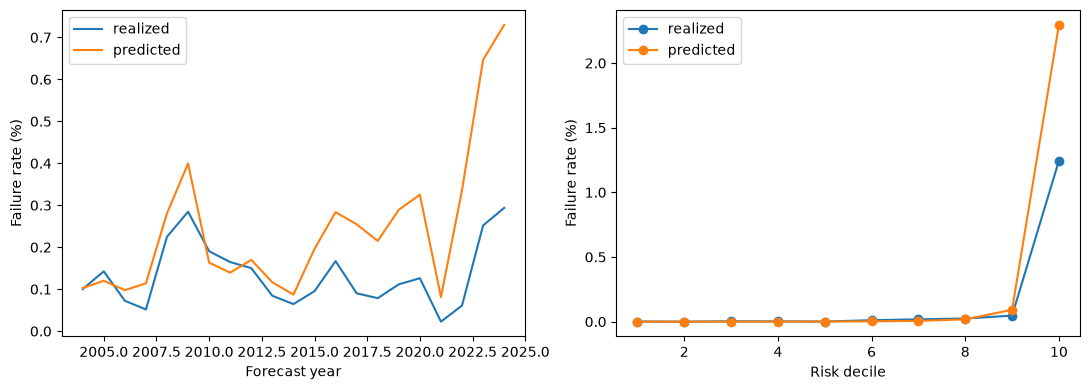

In [5]:
known = test.loc[test.labeled].copy()
known["year"] = known.forecast_month.dt.year
known["risk_decile"] = pd.qcut(known.probability.rank(method="first"), 10, labels=False) + 1
annual = known.groupby("year").agg(realized=("target", "mean"), predicted=("probability", "mean"), n=("target", "size"))
deciles = known.groupby("risk_decile").agg(realized=("target", "mean"), predicted=("probability", "mean"), n=("target", "size"))
profiles = known.groupby("risk_decile")[features].median()
annual.to_csv(out / "annual_rates.csv")
deciles.to_csv(out / "calibration_deciles.csv")
profiles.to_csv(out / "risk_decile_features.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
(annual[["realized", "predicted"]] * 100).plot(ax=ax[0], ylabel="Failure rate (%)", xlabel="Forecast year")
(deciles[["realized", "predicted"]] * 100).plot(ax=ax[1], marker="o",
                                                ylabel="Failure rate (%)", xlabel="Risk decile")
fig.tight_layout()
fig.savefig(out / "chs_calibration.png", dpi=180)
plt.show()

## Part VII — Robustness and prediction export

Compare the frozen baseline across market regimes. Refit on observations with finite SIGMA and compare both specifications on the same test rows. The complete-case model scores only eligible rows.

In [6]:
regimes = [{"period": f"{start}–{end}", **evaluate(known.loc[known.year.between(start, end)], metrics["threshold"])}
           for start, end in [(2004, 2007), (2008, 2009), (2010, 2019), (2020, 2020), (2021, 2024)]]
pd.DataFrame(regimes).to_csv(out / "regime_robustness.csv", index=False)
# Refit without imputed SIGMA. Compare against the main model on the identical test rows.
complete = panel.loc[np.isfinite(panel.sigma)]
cc_test, cc_metrics, *_ = run(complete, features)
common = known.loc[known.set_index(["permno", "forecast_month"]).index.isin(
    cc_test.set_index(["permno", "forecast_month"]).index)]
pd.DataFrame([{"model": "main, matched rows", **evaluate(common, metrics["threshold"])},
              {"model": "complete case refit", **cc_metrics}]).to_csv(
                  out / "complete_case_robustness.csv", index=False)

display(pd.read_csv(out / "regime_robustness.csv"))
display(pd.read_csv(out / "complete_case_robustness.csv"))

,period,n,events,realized,predicted,threshold,roc_auc,average_precision,brier,log_loss,...,fp,fn,tn,precision,recall,specificity,f1,monthly_top_1pct_capture,monthly_top_5pct_capture,monthly_top_10pct_capture
0,2004–2007,222359,205,0.000922,0.001086,0.0693,0.959414,0.070476,0.000883,0.004790,...,599,143,221555,0.093797,0.302439,0.997304,0.143187,0.595122,0.824390,0.882927
1,2008–2009,102452,260,0.002538,0.003381,0.0693,0.960835,0.087789,0.002408,0.011519,...,1059,148,101133,0.095645,0.430769,0.989637,0.156534,0.400000,0.815385,0.919231
2,2010–2019,436331,527,0.001208,0.001905,0.0693,0.968231,0.075471,0.001168,0.006071,...,2223,324,433581,0.083677,0.385199,0.994899,0.137487,0.516129,0.869070,0.924099
3,2020–2020,42042,53,0.001261,0.003250,0.0693,0.972530,0.101702,0.001249,0.006890,...,431,23,41558,0.065076,0.566038,0.989735,0.116732,0.528302,0.830189,0.905660
4,2021–2024,183736,290,0.001578,0.004511,0.0693,0.957967,0.051076,0.001689,0.009445,...,2823,151,180623,0.046928,0.479310,0.984611,0.085486,0.265517,0.696552,0.855172


,model,n,events,realized,predicted,threshold,roc_auc,average_precision,brier,log_loss,...,fp,fn,tn,precision,recall,specificity,f1,monthly_top_1pct_capture,monthly_top_5pct_capture,monthly_top_10pct_capture
0,"main, matched rows",986814,1335,0.001353,0.002416,0.069300,0.963991,0.065312,0.001333,0.007012,...,7135,789,978344,0.071084,0.408989,0.992760,0.121118,0.451685,0.812734,0.901124
1,complete case refit,986814,1335,0.001353,0.002147,0.062802,0.965163,0.068783,0.001316,0.006826,...,6970,780,978509,0.073754,0.415730,0.992927,0.125282,0.471161,0.822472,0.903371


In [7]:
predictions = test[identifiers + ["probability"]].merge(
    cc_test[["permno", "forecast_month", "probability"]].rename(
        columns={"probability": "complete_case_probability"}),
    on=["permno", "forecast_month"], how="left", validate="one_to_one")
predictions.to_parquet(out / "chs_predictions.parquet", index=False)
print(f"Exported {len(predictions):,} forecasts.")

Exported 986,920 forecasts.
